dimensionless

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

L = 3.0
H = 1.0
nx = 150
ny = 100
dx = L / (nx - 1)
dy = H / (ny - 1)


dt = 0.001
nt = 5001
nit = 200

In [9]:
x = np.linspace(0, L, nx)
y = np.linspace(0, H, ny)
X, Y = np.meshgrid(x, y)

u = np.zeros((ny, nx))
v = np.zeros((ny, nx))
p = np.zeros((ny, nx))   # gh
omega_z = np.zeros((ny, nx))

from PIL import Image

obstacle1 = (X - 0.5)**2 + (Y - 0.5)**2 < 0.2**2
obstacle2 = (X - 2.0)**2 + (Y - 0.8)**2 < 0.2**2

mask = np.ones((ny, nx))
mask[obstacle1] = 0.0
mask[obstacle2] = 0.0


In [20]:

def velocity_bc(u, v):

    u[:, 0] = 1.0
    v[:, 0] = 0.0

    u[:, -1] = u[:, -2]
    v[:, -1] = v[:, -2]

    u[0, :] = 0.0
    u[-1, :] = 0.0
    v[0, :] = 0.0
    v[-1, :] = 0.0

    u[obstacle1] = 0.0 ; u[obstacle2] = 0.0
    v[obstacle1] = 0.0 ; v[obstacle2] = 0.0
    
    return u, v

def pressure_bc(p):

    p[0, :] = p[1, :]
    p[-1, :] = p[-2, :]

    p[:, 0] = p[:, 1]

    p[:, -1] = 0.0
    
    return p

def solve_pressure(p, u, v, dx, dy, dt, nit):

    b = np.zeros_like(p)
    b[1:-1, 1:-1] = (1 / dt) * (
        (u[1:-1, 2:] - u[1:-1, :-2]) / (2 * dx) +
        (v[2:, 1:-1] - v[:-2, 1:-1]) / (2 * dy)
    )
    
    b[obstacle1] = 0.0 ; b[obstacle2] = 0.0

    omega_z[1:-1, 1:-1] = (
        (v[1:-1, 2:] - v[1:-1, :-2]) / (2 * dx) -   # ∂v/∂x 
        (u[2:, 1:-1] - u[:-2, 1:-1]) / (2 * dy)     # ∂u/∂y
        )

    omega_z[obstacle1] = 0.0 ; omega_z[obstacle2] = 0.0
    
    # Gauss-Seidel iteration
    for _ in range(nit):
        p_old = p.copy()
        
        # Update interior points
        p[1:-1, 1:-1] = (
            (p[1:-1, 2:] + p[1:-1, :-2]) * dy**2 +
            (p[2:, 1:-1] + p[:-2, 1:-1]) * dx**2 -
            b[1:-1, 1:-1] * dx**2 * dy**2
        ) / (2 * (dx**2 + dy**2))
        
        p[obstacle1] = 0.0 ; p[obstacle2] = 0.0

        p = pressure_bc(p)
    
    return p, omega_z

def intermediate_velocity(u, v, dx, dy, dt, Re):

    u_star = u.copy()
    v_star = v.copy()
    
    # Advection terms
    du_dx = (u[1:-1, 2:] - u[1:-1, :-2]) / (2 * dx)
    du_dy = (u[2:, 1:-1] - u[:-2, 1:-1]) / (2 * dy)
    dv_dx = (v[1:-1, 2:] - v[1:-1, :-2]) / (2 * dx)
    dv_dy = (v[2:, 1:-1] - v[:-2, 1:-1]) / (2 * dy)
    
    # Diffusion terms
    d2u_dx2 = (u[1:-1, 2:] - 2*u[1:-1, 1:-1] + u[1:-1, :-2]) / dx**2
    d2u_dy2 = (u[2:, 1:-1] - 2*u[1:-1, 1:-1] + u[:-2, 1:-1]) / dy**2
    d2v_dx2 = (v[1:-1, 2:] - 2*v[1:-1, 1:-1] + v[1:-1, :-2]) / dx**2
    d2v_dy2 = (v[2:, 1:-1] - 2*v[1:-1, 1:-1] + v[:-2, 1:-1]) / dy**2

    u_star[1:-1, 1:-1] = (
        u[1:-1, 1:-1]
        + dt * (-u[1:-1, 1:-1] * du_dx - v[1:-1, 1:-1] * du_dy)
        + dt * (1/Re) * (d2u_dx2 + d2u_dy2)
    )
    v_star[1:-1, 1:-1] = (
        v[1:-1, 1:-1]
        + dt * (-u[1:-1, 1:-1] * dv_dx - v[1:-1, 1:-1] * dv_dy)
        + dt * (1/Re) * (d2v_dx2 + d2v_dy2)
    )
    
    u_star[obstacle1] = 0.0 ; u_star[obstacle2] = 0.0
    v_star[obstacle1] = 0.0 ; v_star[obstacle2] = 0.0
    
    return u_star, v_star

def correct_velocity(u_star, v_star, p, dx, dy, dt):

    u_new = u_star.copy()
    v_new = v_star.copy()
    
    dp_dx = (p[1:-1, 2:] - p[1:-1, :-2]) / (2 * dx)
    dp_dy = (p[2:, 1:-1] - p[:-2, 1:-1]) / (2 * dy)
    
    u_new[1:-1, 1:-1] = u_star[1:-1, 1:-1] - (dt) * dp_dx
    v_new[1:-1, 1:-1] = v_star[1:-1, 1:-1] - (dt) * dp_dy
    
    u_new[obstacle1] = 0.0 ; u_new[obstacle2] = 0.0
    v_new[obstacle1] = 0.0 ; v_new[obstacle2] = 0.0
    
    return u_new, v_new


In [27]:


# 1
snapshots_1 = {}
u = np.zeros((ny, nx))
v = np.zeros((ny, nx))
p_1 = np.zeros((ny, nx))
Re = 100

for n in range(nt):
    u_1, v_1 = velocity_bc(u, v)
    u_star_1, v_star_1 = intermediate_velocity(u_1, v_1, dx, dy, dt, Re)
    p_1, o = solve_pressure(p_1, u_star_1, v_star_1, dx, dy, dt, nit)
    u_cor_1, v_cor_1 = correct_velocity(u_star_1, v_star_1, p_1, dx, dy, dt)
    u, v = velocity_bc(u_cor_1, v_cor_1)
    
    if n in [2000, 3500, 5000]:
            snapshots_1[n] = (u.copy(), v.copy(), o.copy())

# 2
snapshots_2 = {}
u = np.zeros((ny, nx))
v = np.zeros((ny, nx))
p_2 = np.zeros((ny, nx))
Re = 300

for n in range(nt):
    u_2, v_2 = velocity_bc(u, v)
    u_star_2, v_star_2 = intermediate_velocity(u_2, v_2, dx, dy, dt, Re)
    p_2, o = solve_pressure(p_2, u_star_2, v_star_2, dx, dy, dt, nit)
    u_cor_2, v_cor_2 = correct_velocity(u_star_2, v_star_2, p_2, dx, dy, dt)
    u, v = velocity_bc(u_cor_2, v_cor_2)
    
    if n in [2000, 3500, 5000]:
            snapshots_2[n] = (u.copy(), v.copy(), o.copy())

# 3
snapshots_3 = {}
u = np.zeros((ny, nx))
v = np.zeros((ny, nx))
p_3 = np.zeros((ny, nx))
Re = 500

for n in range(nt):
    u_3, v_3 = velocity_bc(u, v)
    u_star_3, v_star_3 = intermediate_velocity(u_3, v_3, dx, dy, dt, Re)
    p_3, o = solve_pressure(p_3, u_star_3, v_star_3, dx, dy, dt, nit)
    u_cor_3, v_cor_3 = correct_velocity(u_star_3, v_star_3, p_3, dx, dy, dt)
    u, v = velocity_bc(u_cor_3, v_cor_3)
    
    if n in [2000, 3500, 5000]:
            snapshots_3[n] = (u.copy(), v.copy(), o.copy())

# 4
snapshots_4 = {}
u = np.zeros((ny, nx))
v = np.zeros((ny, nx))
p_4 = np.zeros((ny, nx))
Re = 700

for n in range(nt):
    u_4, v_4 = velocity_bc(u, v)
    u_star_4, v_star_4 = intermediate_velocity(u_4, v_4, dx, dy, dt, Re)
    p_4, o = solve_pressure(p_4, u_star_4, v_star_4, dx, dy, dt, nit)
    u_cor_4, v_cor_4 = correct_velocity(u_star_4, v_star_4, p_4, dx, dy, dt)
    u, v = velocity_bc(u_cor_4, v_cor_4)
    
    if n in [2000, 3500, 5000]:
            snapshots_4[n] = (u.copy(), v.copy(), o.copy())

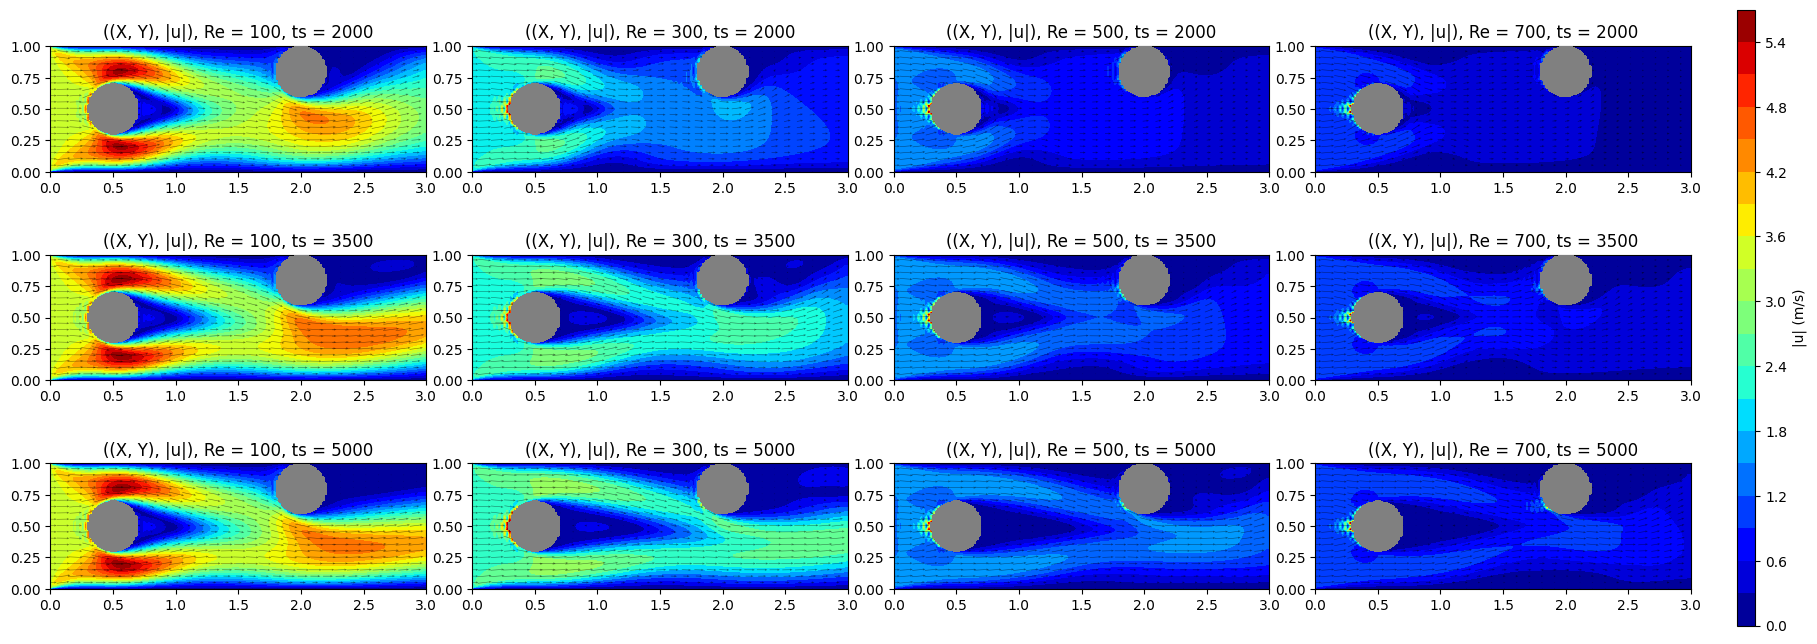

In [22]:
import matplotlib.pyplot as plt
import numpy as np

quiver_step = 5
scale = 30
width = 0.0015
headwidth = 3.8
headlength = 4.5
headaxislength = 4.0

plot_steps = [2000, 3500, 5000]


fig = plt.figure(figsize=(22, 8))
gs = fig.add_gridspec(3, 5, width_ratios=[1, 1, 1, 1, 0.05], wspace=0.15, hspace=0.05)

ax1 = fig.add_subplot(gs[0, 0]) ; ax4 = fig.add_subplot(gs[0, 1]) ; ax7 = fig.add_subplot(gs[0, 2]) ; ax10 = fig.add_subplot(gs[0, 3])
ax2 = fig.add_subplot(gs[1, 0]) ; ax5 = fig.add_subplot(gs[1, 1]) ; ax8 = fig.add_subplot(gs[1, 2]) ; ax11 = fig.add_subplot(gs[1, 3])
ax3 = fig.add_subplot(gs[2, 0]) ; ax6 = fig.add_subplot(gs[2, 1]) ; ax9 = fig.add_subplot(gs[2, 2]) ; ax12 = fig.add_subplot(gs[2, 3])
cbar_ax = fig.add_subplot(gs[:, 4])

axes1 = [ax1, ax2, ax3] ; axes2 = [ax4, ax5, ax6] ; axes3 = [ax7, ax8, ax9] ; axes4 = [ax10, ax11, ax12]

for idx, step in enumerate(plot_steps):
    u_t, v_t = snapshots_1[step]
    speed = np.sqrt(u_t**2 + v_t**2)
    noise = np.random.uniform(-0.01, 0.01, size=u.shape)
    u_t += noise
    v_t += noise
    
    x_sub = X[::quiver_step, ::quiver_step]
    y_sub = Y[::quiver_step, ::quiver_step]
    u_sub = u_t[::quiver_step, ::quiver_step]
    v_sub = v_t[::quiver_step, ::quiver_step]
    
    ax = axes1[idx]
    cf = ax.contourf(X, Y, speed, levels=20, cmap='jet')
    ax.contourf(X, Y, obstacle1, levels=[0.5, 1.5], colors='gray', zorder=3)
    ax.contourf(X, Y, obstacle2, levels=[0.5, 1.5], colors='gray', zorder=4)
    ax.quiver(x_sub, y_sub, u_sub, v_sub,
                  scale=scale, width=width, alpha=0.5,
                  headwidth=headwidth, headlength=headlength, headaxislength=headaxislength,
                  color='black', pivot='mid', zorder=2)  
    ax.set_title(f'((X, Y), |u|), Re = 100, ts = {step}')
    ax.set_aspect('equal')


for idx, step in enumerate(plot_steps):
    u_t, v_t = snapshots_2[step]
    speed = np.sqrt(u_t**2 + v_t**2)
    noise = np.random.uniform(-0.01, 0.01, size=u.shape)
    u_t += noise
    v_t += noise
    
    x_sub = X[::quiver_step, ::quiver_step]
    y_sub = Y[::quiver_step, ::quiver_step]
    u_sub = u_t[::quiver_step, ::quiver_step]
    v_sub = v_t[::quiver_step, ::quiver_step]
    
    ax = axes2[idx]
    cf = ax.contourf(X, Y, speed, levels=20, cmap='jet')
    ax.contourf(X, Y, obstacle1, levels=[0.5, 1.5], colors='gray', zorder=3)
    ax.contourf(X, Y, obstacle2, levels=[0.5, 1.5], colors='gray', zorder=4)
    ax.quiver(x_sub, y_sub, u_sub, v_sub,
                  scale=scale, width=width, alpha=0.5,
                  headwidth=headwidth, headlength=headlength, headaxislength=headaxislength,
                  color='black', pivot='mid', zorder=2)  
    ax.set_title(f'((X, Y), |u|), Re = 300, ts = {step}')
    ax.set_aspect('equal')


for idx, step in enumerate(plot_steps):
    u_t, v_t = snapshots_3[step]
    speed = np.sqrt(u_t**2 + v_t**2)
    noise = np.random.uniform(-0.01, 0.01, size=u.shape)
    u_t += noise
    v_t += noise
    
    x_sub = X[::quiver_step, ::quiver_step]
    y_sub = Y[::quiver_step, ::quiver_step]
    u_sub = u_t[::quiver_step, ::quiver_step]
    v_sub = v_t[::quiver_step, ::quiver_step]
    
    ax = axes3[idx]
    cf = ax.contourf(X, Y, speed, levels=20, cmap='jet')
    ax.contourf(X, Y, obstacle1, levels=[0.5, 1.5], colors='gray', zorder=3)
    ax.contourf(X, Y, obstacle2, levels=[0.5, 1.5], colors='gray', zorder=4)
    ax.quiver(x_sub, y_sub, u_sub, v_sub,
                  scale=scale, width=width, alpha=0.5,
                  headwidth=headwidth, headlength=headlength, headaxislength=headaxislength,
                  color='black', pivot='mid', zorder=2)  
    ax.set_title(f'((X, Y), |u|), Re = 500, ts = {step}')
    ax.set_aspect('equal')


for idx, step in enumerate(plot_steps):
    u_t, v_t = snapshots_4[step]
    speed = np.sqrt(u_t**2 + v_t**2)
    noise = np.random.uniform(-0.01, 0.01, size=u.shape)
    u_t += noise
    v_t += noise
    
    x_sub = X[::quiver_step, ::quiver_step]
    y_sub = Y[::quiver_step, ::quiver_step]
    u_sub = u_t[::quiver_step, ::quiver_step]
    v_sub = v_t[::quiver_step, ::quiver_step]
    
    ax = axes4[idx]
    cf = ax.contourf(X, Y, speed, levels=20, cmap='jet')
    ax.contourf(X, Y, obstacle1, levels=[0.5, 1.5], colors='gray', zorder=3)
    ax.contourf(X, Y, obstacle2, levels=[0.5, 1.5], colors='gray', zorder=4)
    ax.quiver(x_sub, y_sub, u_sub, v_sub,
                  scale=scale, width=width, alpha=0.5,
                  headwidth=headwidth, headlength=headlength, headaxislength=headaxislength,
                  color='black', pivot='mid', zorder=2)  
    ax.set_title(f'((X, Y), |u|), Re = 700, ts = {step}')
    ax.set_aspect('equal')


cbar = fig.colorbar(cf, cax=cbar_ax)
cbar.set_label('|u| (m/s)', fontsize=10)

plt.show()

o1 = 68.0784673792856
o1 = 67.25848008503544
o1 = 67.41663789338686
o2 = 126.46287503055578
o2 = 123.03072093181353
o2 = 122.61380007097038
o3 = 221.11858948790461
o3 = 205.55576303021547
o3 = 202.7556119478825
o4 = 357.37807320905017
o4 = 337.73839450613514
o4 = 332.36789027793475


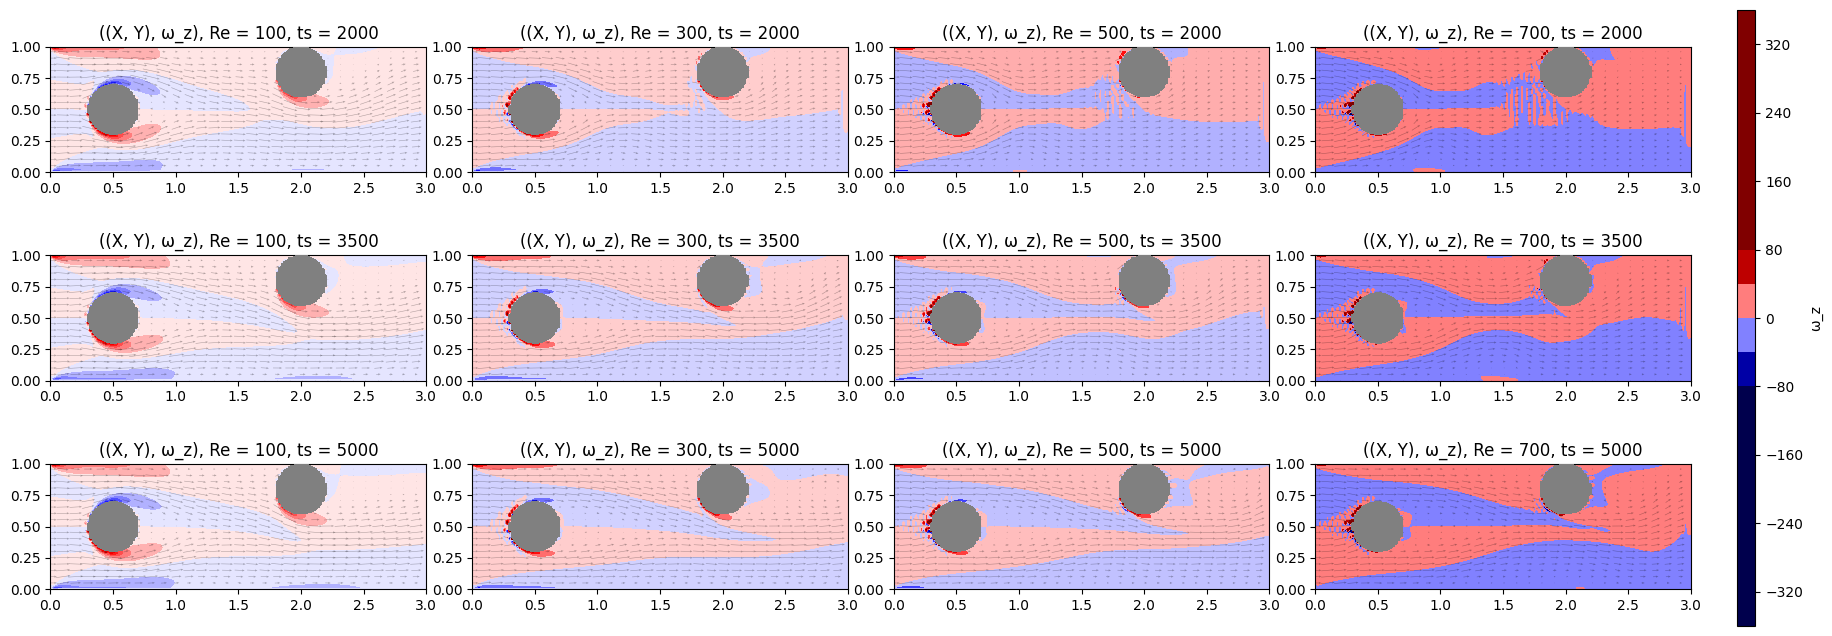

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

quiver_step = 5
scale = 30
width = 0.0015
headwidth = 3.8
headlength = 4.5
headaxislength = 4.0

plot_steps = [2000, 3500, 5000]


fig = plt.figure(figsize=(22, 8))
gs = fig.add_gridspec(3, 5, width_ratios=[1, 1, 1, 1, 0.05], wspace=0.15, hspace=0.05)

ax1 = fig.add_subplot(gs[0, 0]) ; ax4 = fig.add_subplot(gs[0, 1]) ; ax7 = fig.add_subplot(gs[0, 2]) ; ax10 = fig.add_subplot(gs[0, 3])
ax2 = fig.add_subplot(gs[1, 0]) ; ax5 = fig.add_subplot(gs[1, 1]) ; ax8 = fig.add_subplot(gs[1, 2]) ; ax11 = fig.add_subplot(gs[1, 3])
ax3 = fig.add_subplot(gs[2, 0]) ; ax6 = fig.add_subplot(gs[2, 1]) ; ax9 = fig.add_subplot(gs[2, 2]) ; ax12 = fig.add_subplot(gs[2, 3])
cbar_ax = fig.add_subplot(gs[:, 4])

axes1 = [ax1, ax2, ax3] ; axes2 = [ax4, ax5, ax6] ; axes3 = [ax7, ax8, ax9] ; axes4 = [ax10, ax11, ax12]
vmin, vmax = -80, 80

for idx, step in enumerate(plot_steps):
    u_t, v_t, o_t = snapshots_1[step]
    print(f'o1 = {np.max(o_t)}')
    speed = np.sqrt(u_t**2 + v_t**2)
    noise = np.random.uniform(-0.01, 0.01, size=u.shape)
    u_t += noise
    v_t += noise
    
    x_sub = X[::quiver_step, ::quiver_step]
    y_sub = Y[::quiver_step, ::quiver_step]
    u_sub = u_t[::quiver_step, ::quiver_step]
    v_sub = v_t[::quiver_step, ::quiver_step]
    
    ax = axes1[idx]
    cf = ax.contourf(X, Y, o_t, levels=20, cmap='seismic', vmin=vmin, vmax=vmax)
    ax.contourf(X, Y, obstacle1, levels=[0.5, 1.5], colors='gray', zorder=3)
    ax.contourf(X, Y, obstacle2, levels=[0.5, 1.5], colors='gray', zorder=4)
    ax.quiver(x_sub, y_sub, u_sub, v_sub,
                  scale=scale, width=width, alpha=0.3,
                  headwidth=headwidth, headlength=headlength, headaxislength=headaxislength,
                  color='black', pivot='mid', zorder=2)  
    ax.set_title(f'((X, Y), ω_z), Re = 100, ts = {step}')
    ax.set_aspect('equal')


for idx, step in enumerate(plot_steps):
    u_t, v_t, o_t = snapshots_2[step]
    print(f'o2 = {np.max(o_t)}')
    speed = np.sqrt(u_t**2 + v_t**2)
    noise = np.random.uniform(-0.01, 0.01, size=u.shape)
    u_t += noise
    v_t += noise
    
    x_sub = X[::quiver_step, ::quiver_step]
    y_sub = Y[::quiver_step, ::quiver_step]
    u_sub = u_t[::quiver_step, ::quiver_step]
    v_sub = v_t[::quiver_step, ::quiver_step]
    
    ax = axes2[idx]
    cf = ax.contourf(X, Y, o_t, levels=20, cmap='seismic', vmin=vmin, vmax=vmax)
    ax.contourf(X, Y, obstacle1, levels=[0.5, 1.5], colors='gray', zorder=3)
    ax.contourf(X, Y, obstacle2, levels=[0.5, 1.5], colors='gray', zorder=4)
    ax.quiver(x_sub, y_sub, u_sub, v_sub,
                  scale=scale, width=width, alpha=0.3,
                  headwidth=headwidth, headlength=headlength, headaxislength=headaxislength,
                  color='black', pivot='mid', zorder=2)  
    ax.set_title(f'((X, Y), ω_z), Re = 300, ts = {step}')
    ax.set_aspect('equal')


for idx, step in enumerate(plot_steps):
    u_t, v_t, o_t = snapshots_3[step]
    print(f'o3 = {np.max(o_t)}')
    speed = np.sqrt(u_t**2 + v_t**2)
    noise = np.random.uniform(-0.01, 0.01, size=u.shape)
    u_t += noise
    v_t += noise
    
    x_sub = X[::quiver_step, ::quiver_step]
    y_sub = Y[::quiver_step, ::quiver_step]
    u_sub = u_t[::quiver_step, ::quiver_step]
    v_sub = v_t[::quiver_step, ::quiver_step]
    
    ax = axes3[idx]
    cf = ax.contourf(X, Y, o_t, levels=20, cmap='seismic', vmin=vmin, vmax=vmax)
    ax.contourf(X, Y, obstacle1, levels=[0.5, 1.5], colors='gray', zorder=3)
    ax.contourf(X, Y, obstacle2, levels=[0.5, 1.5], colors='gray', zorder=4)
    ax.quiver(x_sub, y_sub, u_sub, v_sub,
                  scale=scale, width=width, alpha=0.3,
                  headwidth=headwidth, headlength=headlength, headaxislength=headaxislength,
                  color='black', pivot='mid', zorder=2)  
    ax.set_title(f'((X, Y), ω_z), Re = 500, ts = {step}')
    ax.set_aspect('equal')


for idx, step in enumerate(plot_steps):
    u_t, v_t, o_t = snapshots_4[step]
    print(f'o4 = {np.max(o_t)}')
    speed = np.sqrt(u_t**2 + v_t**2)
    noise = np.random.uniform(-0.01, 0.01, size=u.shape)
    u_t += noise
    v_t += noise
    
    x_sub = X[::quiver_step, ::quiver_step]
    y_sub = Y[::quiver_step, ::quiver_step]
    u_sub = u_t[::quiver_step, ::quiver_step]
    v_sub = v_t[::quiver_step, ::quiver_step]
    
    ax = axes4[idx]
    cf = ax.contourf(X, Y, o_t, levels=20, cmap='seismic', vmin=vmin, vmax=vmax)
    ax.contourf(X, Y, obstacle1, levels=[0.5, 1.5], colors='gray', zorder=3)
    ax.contourf(X, Y, obstacle2, levels=[0.5, 1.5], colors='gray', zorder=4)
    ax.quiver(x_sub, y_sub, u_sub, v_sub,
                  scale=scale, width=width, alpha=0.3,
                  headwidth=headwidth, headlength=headlength, headaxislength=headaxislength,
                  color='black', pivot='mid', zorder=2)  
    ax.set_title(f'((X, Y), ω_z), Re = 700, ts = {step}')
    ax.set_aspect('equal')


cbar = fig.colorbar(cf, cax=cbar_ax)
cbar.set_label('ω_z', fontsize=10)

plt.show()